# TFS digital twin: quickstart
* `twin.tfs`: offline `tfs`, same API as in hutch-python.
* `twin.mfx_sim`: Matt's MFX wavefront model. `twin.beamline` is `twin.mfx_sim.beamline`.

Goal: focus at the IP, and every inserted lens centered on the beam (rings centered and concentric on the YAGs).

In [1]:
%matplotlib inline
import logging
logging.getLogger("tfs").setLevel(logging.CRITICAL)  # mute "TFS combo may be forbidden"

from tfs_twin import DigitalTwin, SimCamera

## Aligned transfocator

Pre-focussing lens for 9500 eV:
SimPrefocusLens(SIM::DIA:01, name=tfs_sim_prefocus_bot)

Radius: 750.0 um


+-------------+-----------+-----------+
| Prefix      | Radius    | Z         |
+-------------+-----------+-----------+
| SIM::DIA:01 | 750.00000 | 360.00000 |
| SIM::TFS:04 | 250       | 395.64499 |
| SIM::TFS:06 | 125       | 395.79499 |
| SIM::TFS:07 | 62.50000  | 395.86999 |
+-------------+-----------+-----------+

E0 = 9500.0 eV

focus - nominal_sample = -5.59 mm

tfs_04: dx =   +0.0 um, dy =   +0.0 um

tfs_06: dx =   +0.0 um, dy =   +0.0 um

tfs_07: dx =   +0.0 um, dy =   +0.0 um

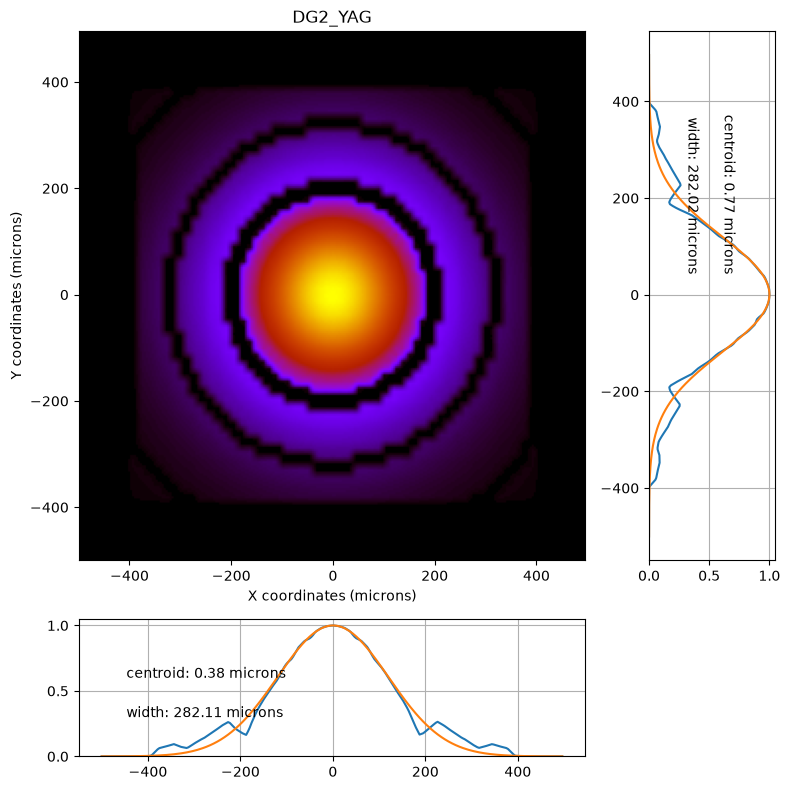

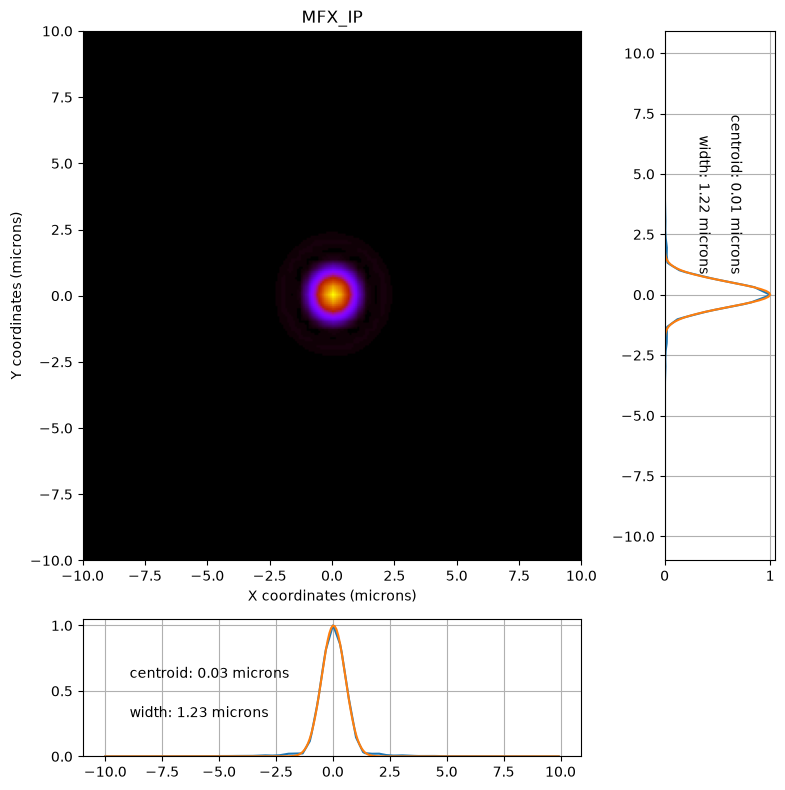

In [2]:
twin = DigitalTwin(9500, N=256, misalignment=0)
tfs = twin.tfs

tfs.focus_at(energy_eV=9500, wait=True)
twin.propagate()
twin.beamline.DG2_YAG.view_beam()
twin.beamline.MFX_IP.view_beam()
twin.report()

Move the stage like on the real instrument: the TFS lenses move with it and the IP defocuses.

E0 = 9500.0 eV

focus - nominal_sample = -105.39 mm

tfs_04: dx =   +0.0 um, dy =   +0.0 um

tfs_06: dx =   +0.0 um, dy =   +0.0 um

tfs_07: dx =   +0.0 um, dy =   +0.0 um

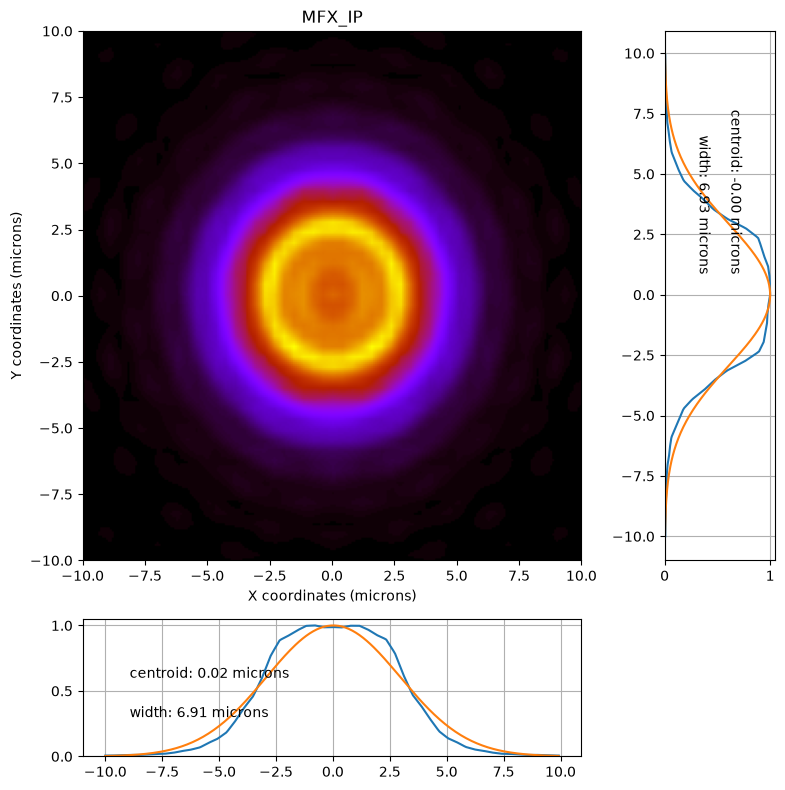

In [3]:
tfs.translation.mvr(-100)
twin.propagate()
twin.beamline.MFX_IP.view_beam()
twin.report()

## Misaligned transfocator
Each lens's true center is hidden within ±50 µm of its motor readback. `twin.report()` shows the truth; use it only for grading.

Pre-focussing lens for 9500 eV:
SimPrefocusLens(SIM::DIA:01, name=tfs_sim_prefocus_bot)

Radius: 750.0 um


+-------------+-----------+-----------+
| Prefix      | Radius    | Z         |
+-------------+-----------+-----------+
| SIM::DIA:01 | 750.00000 | 360.00000 |
| SIM::TFS:04 | 250       | 395.64499 |
| SIM::TFS:06 | 125       | 395.79499 |
| SIM::TFS:07 | 62.50000  | 395.86999 |
+-------------+-----------+-----------+

E0 = 9500.0 eV

focus - nominal_sample = -5.59 mm

tfs_04: dx =  +40.6 um, dy =   +6.7 um

tfs_06: dx =  -23.5 um, dy =  +38.6 um

tfs_07: dx =  +10.9 um, dy =   -1.7 um

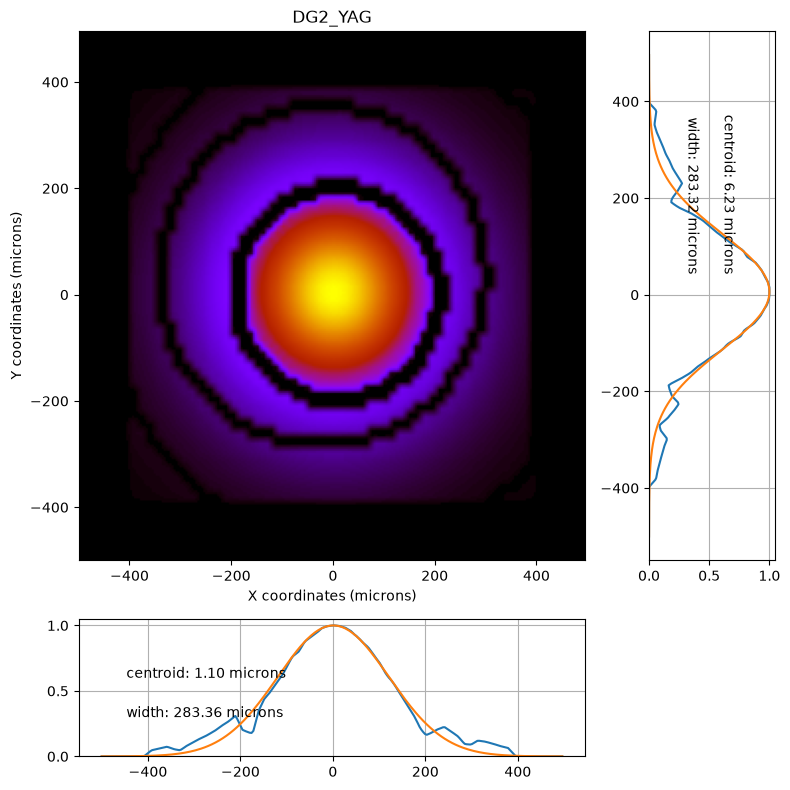

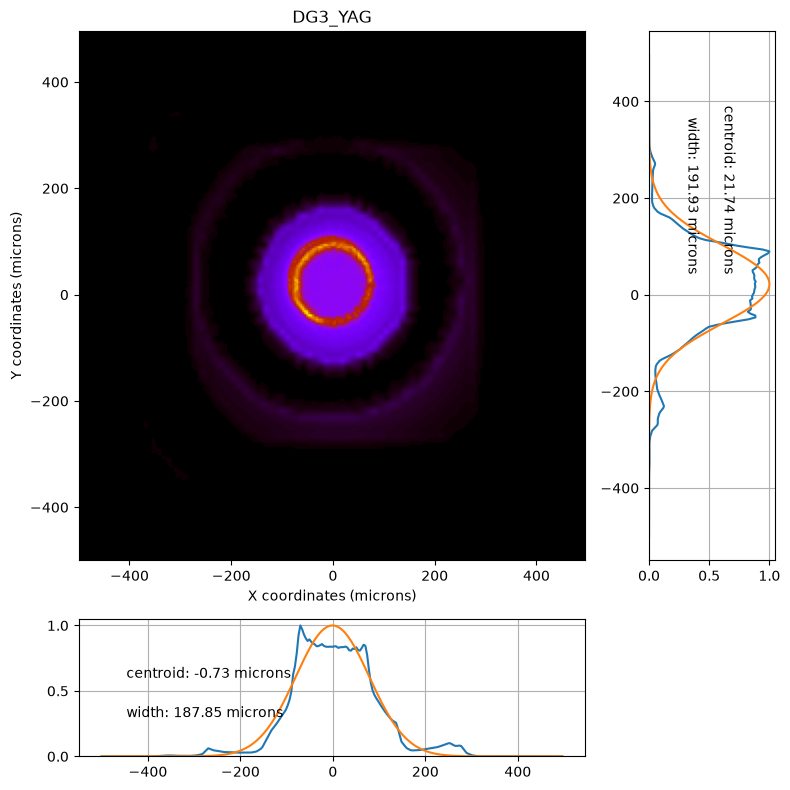

In [4]:
twin = DigitalTwin(9500, N=256, misalignment=50e-6, seed=3)
tfs = twin.tfs
tfs.focus_at(energy_eV=9500, wait=True)
twin.propagate()
twin.beamline.DG2_YAG.view_beam()
twin.beamline.DG3_YAG.view_beam()
twin.report()

## Baseline protocol (`protocols/center_lenses.py`)
Only uses `tfs` and `camera.get_image()`, so the same code runs on the instrument.

tfs_sim_tfs_04_x: -0.0399

tfs_sim_tfs_04_y: -0.0056

tfs_sim_tfs_06_x: 0.0241

tfs_sim_tfs_06_y: -0.0377

tfs_sim_tfs_07_x: -0.0101

...

E0 = 9500.0 eV

focus - nominal_sample = -5.59 mm

tfs_04: dx =   +0.7 um, dy =   +1.1 um

tfs_06: dx =   +0.7 um, dy =   +0.9 um

tfs_07: dx =   +0.8 um, dy =   +1.1 um

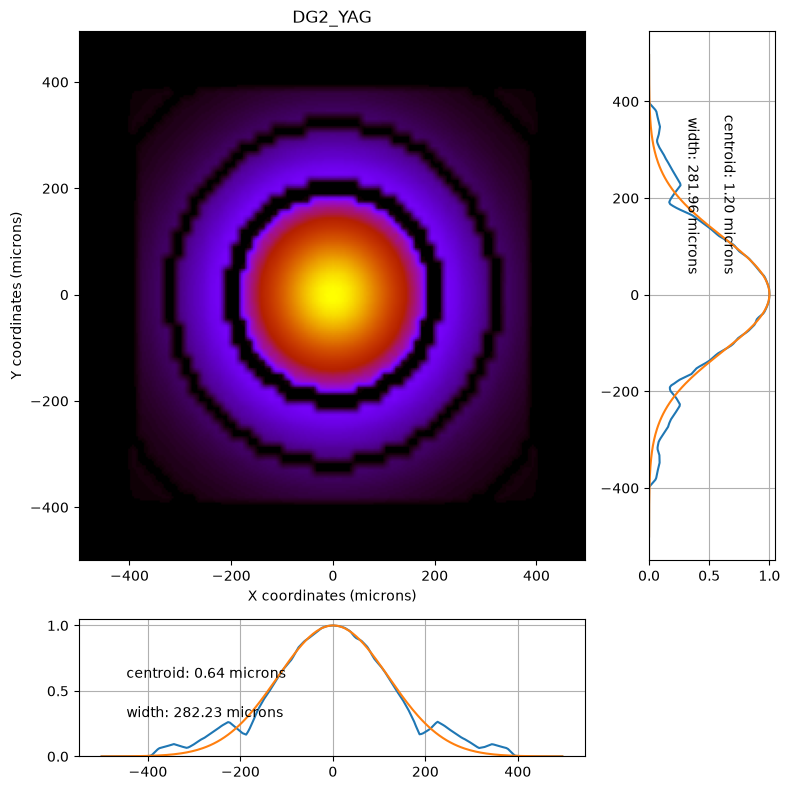

In [5]:
from protocols.center_lenses import center_lenses

camera = SimCamera(twin, "DG3_YAG", noise=True)
center_lenses(tfs, camera, lenses=[lens for lens in tfs.tfs_lenses if lens.inserted])
twin.propagate()
twin.beamline.DG2_YAG.view_beam()
twin.report()

## On the real instrument (hutch-python)
```python
from tfs_twin import snapshot, make_tfs_sim
snapshot(tfs)                 # read-only, saves snapshots/latest.json
tfs_sim = make_tfs_sim(tfs)   # offline copy of the live geometry
```